In [1]:

print("Hello Posture AI!")

a = 10
b = 20

print("a + b =", a + b)


Hello Posture AI!
a + b = 30


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("라이브러리 준비 완료!")


라이브러리 준비 완료!


In [3]:

import numpy as np
import pandas as pd

# 1. 측정 조건
fs = 50        # 1초에 50번 측정
duration = 20  # 총 20초

# 2. 시간 데이터 생성
t = np.arange(0, duration, 1/fs)

# 3. 자세 정답 라벨
# 0 = 중립 자세
# 1 = 전방 굽힘
label = np.where(t < 10, 0, 1)

# 4. 가상 센서 각도 생성
rng = np.random.default_rng(42)

upper = np.where(t < 10, 3.0, 25.0)
lower = np.where(t < 10, 2.0, 8.0)

# 실제 측정처럼 작은 흔들림 추가
upper = upper + rng.normal(0, 0.7, len(t))
lower = lower + rng.normal(0, 0.5, len(t))

# 5. 표 형태로 정리
df = pd.DataFrame({
    "time_s": t,
    "upper_angle": upper,
    "lower_angle": lower,
    "label": label
})

print(df.head())
print("전체 데이터 수:", len(df))


   time_s  upper_angle  lower_angle  label
0    0.00     3.213302     1.970359      0
1    0.02     2.272011     1.635357      0
2    0.04     3.525316     1.792763      0
3    0.06     3.658395     2.316955      0
4    0.08     1.634275     2.001497      0
전체 데이터 수: 1000


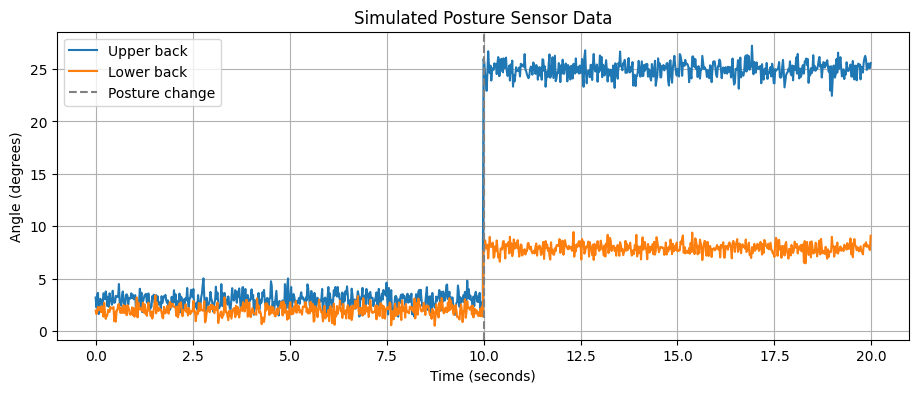

In [4]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 4))

plt.plot(
    df["time_s"],
    df["upper_angle"],
    label="Upper back"
)

plt.plot(
    df["time_s"],
    df["lower_angle"],
    label="Lower back"
)

plt.axvline(
    x=10,
    color="gray",
    linestyle="--",
    label="Posture change"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Angle (degrees)")
plt.title("Simulated Posture Sensor Data")

plt.legend()
plt.grid()
plt.show()


In [5]:

from google.colab import files

# CSV 파일 생성
df.to_csv(
    "posture_sample.csv",
    index=False
)

# 내 컴퓨터로 다운로드
files.download("posture_sample.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>